# Cross-entropy method

Learn the cross-entropy method on discrete Taxi states, then use a neural-network policy for CartPole.

This exercise targets Python 3.12+:

```bash
python -m pip install "gymnasium[classic-control]>=1.3,<2" numpy matplotlib scikit-learn ipython
```


In [1]:
import os
os.environ["SDL_VIDEODRIVER"] = "dummy"
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

SEED = 42
np.random.seed(SEED)
%matplotlib inline

In [2]:
env = gym.make("Taxi-v4", render_mode="ansi")
observation, info = env.reset(seed=SEED)
print(env.render())

+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+




In [3]:
n_states = env.observation_space.n
n_actions = env.action_space.n

print("n_states=%i, n_actions=%i"%(n_states,n_actions))

n_states=500, n_actions=6


# Create stochastic policy

This time our policy should be a probability distribution.

```policy[s,a] = P(take action a | in state s)```

Since we still use integer state and action representations, you can use a 2-dimensional array to represent the policy.

Please initialize policy __uniformly__, that is, probabililities of all actions should be equal.


# Initialize policy (0.5pts)

In [4]:
policy = np.full((n_states, n_actions), 1.0 / n_actions)
assert isinstance(policy, np.ndarray)
assert np.allclose(policy, 1.0 / n_actions)
assert np.allclose(np.sum(policy, axis=1), 1.0)
print("Ok!")

Ok!


# Play the game (0.5pts)

Just like before, but we also record all states and actions we took.

In [5]:
def generate_session(policy, t_max=10**4, use_mask=False):
    states, actions = [], []
    total_reward = 0.0
    state, info = env.reset()

    for _ in range(t_max):
        probs = policy[state].copy()
        if use_mask:
            
            mask = info["action_mask"]
            probs *= mask
            if probs.sum() == 0:
                probs = mask.astype(float)
            probs /= probs.sum()
        action = np.random.choice(n_actions, p=probs)
        next_state, reward, terminated, truncated, info = env.step(action)
        states.append(state)
        actions.append(action)
        total_reward += reward
        state = next_state
        if terminated or truncated:
            break
    return states, actions, total_reward


generate_taxi_session = generate_session

In [6]:
states, actions, reward = generate_session(policy)
assert isinstance(states, list) and isinstance(actions, list)
assert len(states) == len(actions)
assert isinstance(reward, (float, np.floating))

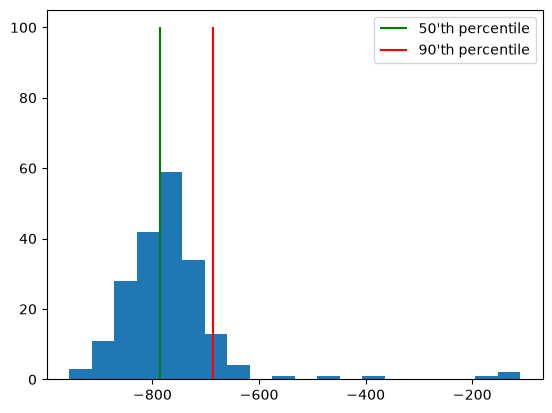

In [7]:
import matplotlib.pyplot as plt
%matplotlib inline

sample_rewards = [generate_session(policy,t_max=1000)[-1] for _ in range(200)]

plt.hist(sample_rewards,bins=20);
plt.vlines([np.percentile(sample_rewards,50)],[0],[100],label="50'th percentile",color='green')
plt.vlines([np.percentile(sample_rewards,90)],[0],[100],label="90'th percentile",color='red')
plt.legend()

### Crossentropy method steps (1pts)

In [8]:
def select_elites(states_batch, actions_batch, rewards_batch, percentile=50):
    reward_threshold = np.percentile(rewards_batch, percentile)
    elite_states, elite_actions = [], []
    for states, actions, reward in zip(states_batch, actions_batch, rewards_batch):
        if reward >= reward_threshold:
            elite_states.extend(states)
            elite_actions.extend(actions)
    return np.asarray(elite_states), np.asarray(elite_actions)

In [9]:
states_batch = [
    [1, 2, 3],       
    [4, 2, 0, 2],    
    [3, 1],          
]
actions_batch = [
    [0, 2, 4],       
    [3, 2, 0, 1],    
    [3, 3],          
]
rewards_batch = np.array([3, 4, 5])

test_result_0 = select_elites(states_batch, actions_batch, rewards_batch, percentile=0)
test_result_30 = select_elites(states_batch, actions_batch, rewards_batch, percentile=30)
test_result_90 = select_elites(states_batch, actions_batch, rewards_batch, percentile=90)
test_result_100 = select_elites(states_batch, actions_batch, rewards_batch, percentile=100)

assert np.array_equal(test_result_0[0], [1, 2, 3, 4, 2, 0, 2, 3, 1])
assert np.array_equal(test_result_0[1], [0, 2, 4, 3, 2, 0, 1, 3, 3])
assert np.array_equal(test_result_30[0], [4, 2, 0, 2, 3, 1])
assert np.array_equal(test_result_30[1], [3, 2, 0, 1, 3, 3])
assert np.array_equal(test_result_90[0], [3, 1])
assert np.array_equal(test_result_90[1], [3, 3])
assert np.array_equal(test_result_100[0], [3, 1])
assert np.array_equal(test_result_100[1], [3, 3])
print("Ok!")

Ok!


In [10]:
def update_policy(elite_states, elite_actions):
    new_policy = np.zeros((n_states, n_actions))
    for state, action in zip(elite_states, elite_actions):
        new_policy[state, action] += 1
    for state in range(n_states):
        count = new_policy[state].sum()
        if count > 0:
            new_policy[state] /= count
        else:
            new_policy[state] = 1.0 / n_actions
    return new_policy

In [11]:
elite_states, elite_actions = ([1, 2, 3, 4, 2, 0, 2, 3, 1], [0, 2, 4, 3, 2, 0, 1, 3, 3])


new_policy = update_policy(elite_states,elite_actions)

assert np.isfinite(new_policy).all(), "Your new policy contains NaNs or +-inf. Make sure you don't divide by zero."
assert np.all(new_policy>=0), "Your new policy can't have negative action probabilities"
assert np.allclose(new_policy.sum(axis=-1),1), "Your new policy should be a valid probability distribution over actions"
reference_answer = np.array([
       [ 1.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.5       ,  0.        ,  0.        ,  0.5       ,  0.        ],
       [ 0.        ,  0.33333333,  0.66666667,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.5       ,  0.5       ]])
print(new_policy[:4,:5])
assert np.allclose(new_policy[:4,:5],reference_answer)
print("Ok!")

[[1.         0.         0.         0.         0.        ]
 [0.5        0.         0.         0.5        0.        ]
 [0.         0.33333333 0.66666667 0.         0.        ]
 [0.         0.         0.         0.5        0.5       ]]
Ok!


# Training loop (1pts)
Generate sessions, select N best and fit to those.

In [12]:
def show_progress(rewards_batch, log, percentile, reward_range=None):

    mean_reward = np.mean(rewards_batch)
    threshold = np.percentile(rewards_batch, percentile)
    log.append((mean_reward, threshold))

    clear_output(wait=True)
    print(f"mean reward = {mean_reward:.3f}, threshold = {threshold:.3f}")
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].plot([row[0] for row in log], label="Mean reward")
    axes[0].plot([row[1] for row in log], label="Elite threshold")
    axes[0].set_xlabel("Iteration")
    axes[0].set_ylabel("Reward")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].hist(rewards_batch, bins=20, range=reward_range)
    axes[1].axvline(threshold, label="Elite threshold", color="red")
    axes[1].set_xlabel("Episode reward")
    axes[1].set_ylabel("Count")
    axes[1].legend()
    axes[1].grid(True)
    plt.tight_layout()
    plt.show()

In [13]:
policy = np.full((n_states, n_actions), 1.0 / n_actions)

Taxi: 20, mean = -131.62


Taxi: 40, mean = -246.40


Taxi: 60, mean = -228.62


Taxi: 80, mean = -268.05


Taxi: 100, mean = -296.71


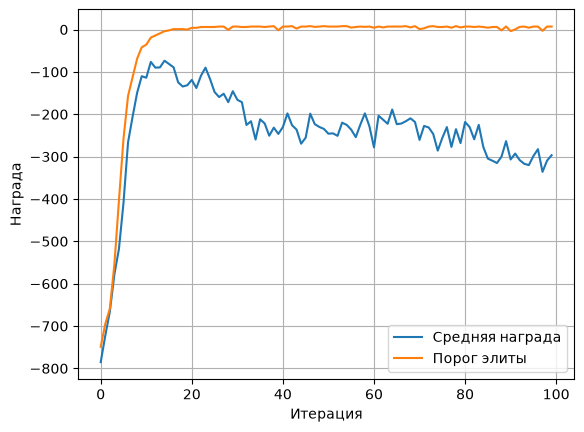

In [14]:
n_sessions = 250
percentile = 70
learning_rate = 0.5
log = []
for iteration in range(100):
    sessions = [generate_session(policy) for _ in range(n_sessions)]
    states_batch, actions_batch, rewards_batch = zip(*sessions)
    elite_states, elite_actions = select_elites(
        states_batch, actions_batch, rewards_batch, percentile)
    new_policy = update_policy(elite_states, elite_actions)
    policy = (1 - learning_rate) * policy + learning_rate * new_policy
    log.append((np.mean(rewards_batch), np.percentile(rewards_batch, percentile)))
    if (iteration + 1) % 20 == 0:
        print(f"Taxi: {iteration + 1}, mean = {log[-1][0]:.2f}")
base_log = np.asarray(log)
plt.plot(base_log[:, 0], label="Средняя награда")
plt.plot(base_log[:, 1], label="Порог элиты")
plt.xlabel("Итерация")
plt.ylabel("Награда")
plt.legend()
plt.grid()
plt.show()

# Tabular crossentropy method

You may have noticed that the taxi problem quickly converges from -100 to a near-optimal score and then descends back into -50/-100. This is in part because the environment has some innate randomness. Namely, the starting points of passenger/driver change from episode to episode.

### Tasks
- __1.1__ (1 pts) Find out how the algorithm performance changes if you change different percentile and different n_samples. - Build graph with different percentiles on the same graph. And second one for sample size
- __1.2__ (1 pts) Tune the algorithm to end up with positive average score.

It's okay to modify the existing code.


In [15]:
env.close()
env = gym.make("Taxi-v4")
state, info = env.reset()
n_states = env.observation_space.n
n_actions = env.action_space.n
policy = np.full((n_states, n_actions), 1.0 / n_actions)

assert isinstance(policy, np.ndarray)
assert np.allclose(policy.sum(axis=1), 1.0)
states, actions, reward = generate_session(policy)
assert isinstance(states, list) and isinstance(actions, list)
assert len(states) == len(actions)
assert isinstance(reward, (float, np.floating))
step_counter = 40

In [16]:
n_sessions = 250
percentiles = [50, 70, 90]
learning_rate = 0.5
mean_rewards_by_percentile = []
for percentile in percentiles:
    np.random.seed(SEED)
    env.reset(seed=SEED)
    policy = np.full((n_states, n_actions), 1.0 / n_actions)
    current_means = []
    for iteration in range(step_counter):
        sessions = [generate_session(policy) for _ in range(n_sessions)]
        states_batch, actions_batch, rewards_batch = zip(*sessions)
        elite_states, elite_actions = select_elites(
            states_batch, actions_batch, rewards_batch, percentile)
        new_policy = update_policy(elite_states, elite_actions)
        policy = (1 - learning_rate) * policy + learning_rate * new_policy
        current_means.append(np.mean(rewards_batch))
    mean_rewards_by_percentile.append(current_means)
    print(f"percentile={percentile}: {current_means[-1]:.2f}")

percentile=50: -43.91


percentile=70: -222.91


percentile=90: -563.90


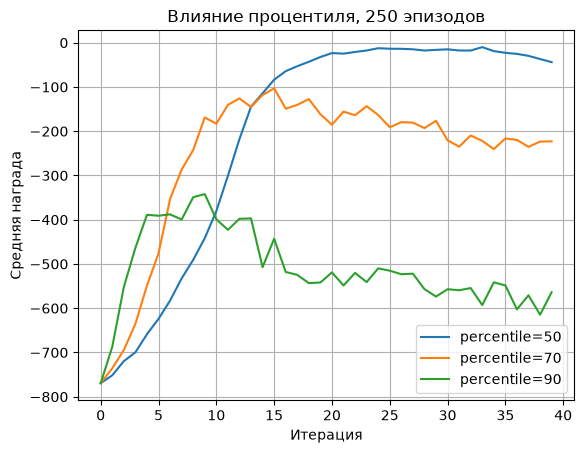

In [17]:
for percentile, rewards in zip(percentiles, mean_rewards_by_percentile):
    plt.plot(rewards, label=f"percentile={percentile}")
plt.xlabel("Итерация")
plt.ylabel("Средняя награда")
plt.title("Влияние процентиля, 250 эпизодов")
plt.legend()
plt.grid()
plt.show()

n_sessions=100: -380.93


n_sessions=250: -222.91


n_sessions=500: -159.97


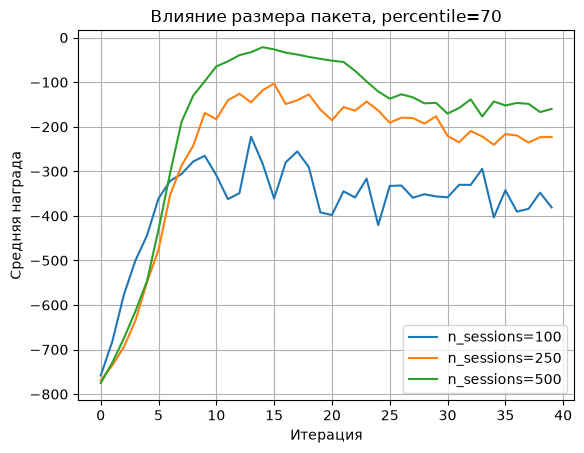

In [18]:
session_counts = [100, 250, 500]
percentile = 70
learning_rate = 0.5
mean_rewards_by_session_count = []
for n_sessions in session_counts:
    np.random.seed(SEED)
    env.reset(seed=SEED)
    policy = np.full((n_states, n_actions), 1.0 / n_actions)
    current_means = []
    for iteration in range(step_counter):
        sessions = [generate_session(policy) for _ in range(n_sessions)]
        states_batch, actions_batch, rewards_batch = zip(*sessions)
        elite_states, elite_actions = select_elites(
            states_batch, actions_batch, rewards_batch, percentile)
        new_policy = update_policy(elite_states, elite_actions)
        policy = (1 - learning_rate) * policy + learning_rate * new_policy
        current_means.append(np.mean(rewards_batch))
    mean_rewards_by_session_count.append(current_means)
    print(f"n_sessions={n_sessions}: {current_means[-1]:.2f}")
for count, rewards in zip(session_counts, mean_rewards_by_session_count):
    plt.plot(rewards, label=f"n_sessions={count}")
plt.xlabel("Итерация")
plt.ylabel("Средняя награда")
plt.title("Влияние размера пакета, percentile=70")
plt.legend()
plt.grid()
plt.show()

# Stabilize positive rewards by averaging policy across 10 games (2 pts)

In [19]:
def generate_session(policy, t_max=10**4):
    
    states, actions, rewards = [], [], []
    for _ in range(10):
        game_states, game_actions, reward = generate_taxi_session(
            policy, t_max=t_max, use_mask=True)
        states.extend(game_states)
        actions.extend(game_actions)
        rewards.append(reward)
    return states, actions, float(np.mean(rewards))

Усреднение: 10, mean = -152.83


Усреднение: 20, mean = -118.44


Усреднение: 30, mean = -88.87


Усреднение: 40, mean = -54.44


Усреднение: 50, mean = -33.06


Усреднение: 60, mean = -16.35


Усреднение: 70, mean = -9.08


Усреднение: 80, mean = -3.51


Усреднение: 90, mean = 0.72


Усреднение: 100, mean = 3.12


Усреднение: 110, mean = 4.90


Средняя награда последних 10 итераций больше 5


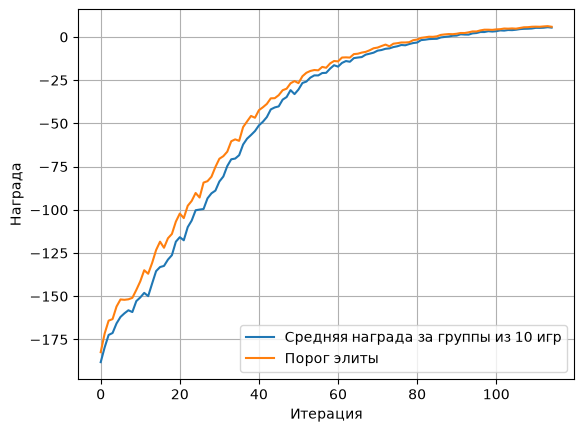

Taxi, 500 новых игр: 5.88
Доля положительных наград: 93.4%


In [20]:
n_sessions = 75  
percentile = 70
learning_rate = 0.5
log = []
mean = []  
policy = np.full((n_states, n_actions), 1.0 / n_actions)
np.random.seed(SEED)
env.reset(seed=SEED)

for iteration in range(150):
    sessions = [generate_session(policy) for _ in range(n_sessions)]
    states_batch, actions_batch, rewards_batch = zip(*sessions)
    elite_states, elite_actions = select_elites(
        states_batch, actions_batch, rewards_batch, percentile)
    new_policy = update_policy(elite_states, elite_actions)
    
    visited = np.zeros(n_states, dtype=bool)
    visited[elite_states] = True
    new_policy[~visited] = policy[~visited]
    mean.append(new_policy)
    mean = mean[-10:]
    averaged_policy = np.mean(mean, axis=0)
    policy = (1 - learning_rate) * policy + learning_rate * averaged_policy
    log.append((np.mean(rewards_batch), np.percentile(rewards_batch, percentile)))
    if (iteration + 1) % 10 == 0:
        print(f"Усреднение: {iteration + 1}, mean = {log[-1][0]:.2f}")
    if len(log) >= 10 and np.mean(np.asarray(log)[-10:, 0]) > 5:
        print("Средняя награда последних 10 итераций больше 5")
        break

taxi_log = np.asarray(log)
taxi_policy = policy.copy()
plt.plot(taxi_log[:, 0], label="Средняя награда за группы из 10 игр")
plt.plot(taxi_log[:, 1], label="Порог элиты")
plt.xlabel("Итерация")
plt.ylabel("Награда")
plt.legend()
plt.grid()
plt.show()


np.random.seed(2026)
env.reset(seed=2026)
taxi_test_rewards = np.array([
    generate_taxi_session(taxi_policy, use_mask=True)[2] for _ in range(500)])
print(f"Taxi, 500 новых игр: {taxi_test_rewards.mean():.2f}")
print(f"Доля положительных наград: {(taxi_test_rewards > 0).mean():.1%}")
assert taxi_test_rewards.mean() > 0
np.save("taxi_policy.npy", taxi_policy)

Количество иттераций для достжения положительного результата возросло, но модель не только достигает большей положительной награды, но и стабильно сохраняет его.

# Digging deeper: approximate crossentropy with neural nets (2 pts)

In this section we will train a neural network policy for continuous state space game

(np.float64(-0.5), np.float64(599.5), np.float64(399.5), np.float64(-0.5))

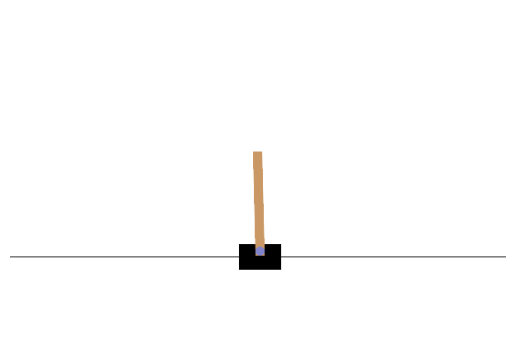

In [21]:
env.close()
env = gym.make("CartPole-v1", render_mode="rgb_array")
initial_observation, info = env.reset()
n_actions = env.action_space.n
plt.imshow(env.render())
plt.axis("off")

In [22]:
from sklearn.neural_network import MLPClassifier
agent = MLPClassifier(
    hidden_layer_sizes=(20, 20), activation="tanh",
    max_iter=1, random_state=SEED)
np.random.seed(SEED)
initial_observation, info = env.reset(seed=SEED)
agent.partial_fit(
    np.repeat(initial_observation[None, :], n_actions, axis=0),
    np.arange(n_actions), classes=np.arange(n_actions))

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(20, ...)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'tanh'
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [23]:
def generate_session(t_max=1000):
    states, actions = [], []
    total_reward = 0.0
    state, info = env.reset()
    for _ in range(t_max):
        probs = agent.predict_proba(state.reshape(1, -1))[0]
        action = np.random.choice(n_actions, p=probs)
        next_state, reward, terminated, truncated, info = env.step(action)
        states.append(state.copy())
        actions.append(action)
        total_reward += reward
        state = next_state
        if terminated or truncated:
            break
    return states, actions, total_reward

In [24]:
def select_elites(states_batch, actions_batch, rewards_batch, percentile=50):

    threshold = np.percentile(rewards_batch, percentile)
    selected = [
        index for index, reward in enumerate(rewards_batch)
        if reward >= threshold
    ]
    elite_states = np.concatenate(
        [np.asarray(states_batch[index]) for index in selected], axis=0
    )
    elite_actions = np.concatenate(
        [np.asarray(actions_batch[index]) for index in selected], axis=0
    )
    return elite_states, elite_actions

CartPole: 10, mean = 43.58


Средняя награда больше 190


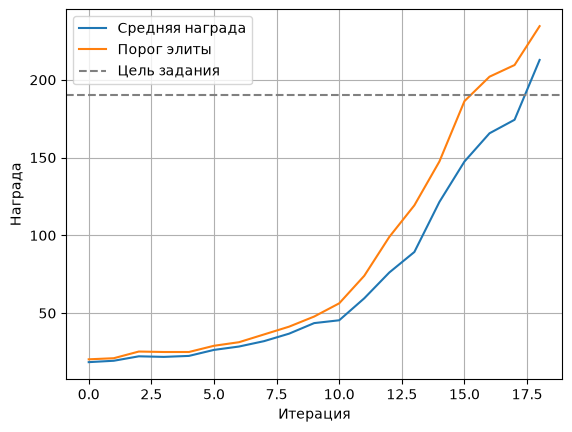

CartPole, 100 новых игр: 238.59


In [25]:
n_sessions = 100
percentile = 70
log = []
for iteration in range(100):
    sessions = [generate_session() for _ in range(n_sessions)]
    states_batch, actions_batch, rewards_batch = zip(*sessions)
    elite_states, elite_actions = select_elites(
        states_batch, actions_batch, rewards_batch, percentile=percentile)
    agent.partial_fit(elite_states, elite_actions)
    log.append((np.mean(rewards_batch), np.percentile(rewards_batch, percentile)))
    if (iteration + 1) % 10 == 0:
        print(f"CartPole: {iteration + 1}, mean = {log[-1][0]:.2f}")
    if np.mean(rewards_batch) > 190:
        print("Средняя награда больше 190")
        break
cartpole_log = np.asarray(log)
plt.plot(cartpole_log[:, 0], label="Средняя награда")
plt.plot(cartpole_log[:, 1], label="Порог элиты")
plt.axhline(190, color="gray", linestyle="--", label="Цель задания")
plt.xlabel("Итерация")
plt.ylabel("Награда")
plt.legend()
plt.grid()
plt.show()
np.random.seed(2026)
env.reset(seed=2026)
cartpole_test_rewards = np.array([generate_session()[2] for _ in range(100)])
print(f"CartPole, 100 новых игр: {cartpole_test_rewards.mean():.2f}")
assert cartpole_test_rewards.mean() > 190
env.close()

# Report (1 pts)

In [26]:
for p, rewards in zip(percentiles, mean_rewards_by_percentile):
    print(f"Процентиль {p}: средняя награда последних 5 итераций = {np.mean(rewards[-5:]):.2f}")
for count, rewards in zip(session_counts, mean_rewards_by_session_count):
    print(f"Пакет {count}: средняя награда последних 5 итераций = {np.mean(rewards[-5:]):.2f}")
print(f"Taxi после настройки: {taxi_test_rewards.mean():.2f}")
print(f"CartPole: {cartpole_test_rewards.mean():.2f}")

import json
results = {
    "percentiles": {str(p): float(np.mean(r[-5:])) for p, r in zip(percentiles, mean_rewards_by_percentile)},
    "session_counts": {str(n): float(np.mean(r[-5:])) for n, r in zip(session_counts, mean_rewards_by_session_count)},
    "taxi_test_mean": float(taxi_test_rewards.mean()),
    "taxi_positive_fraction": float((taxi_test_rewards > 0).mean()),
    "taxi_iterations": len(taxi_log),
    "cartpole_test_mean": float(cartpole_test_rewards.mean()),
    "cartpole_iterations": len(cartpole_log),
    "versions": {"numpy": np.__version__, "gymnasium": gym.__version__},
}
with open("results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

Процентиль 50: средняя награда последних 5 итераций = -31.69
Процентиль 70: средняя награда последних 5 итераций = -223.54
Процентиль 90: средняя награда последних 5 итераций = -580.07
Пакет 100: средняя награда последних 5 итераций = -369.19
Пакет 250: средняя награда последних 5 итераций = -223.54
Пакет 500: средняя награда последних 5 итераций = -154.85
Taxi после настройки: 5.88
CartPole: 238.59
